# 07 — Paper's Original Forward PINN, run directly, evaluated on your 100x100 mesh

This notebook uses the **author's own repo code**
(`https://github.com/ashish1610dhiman/pinn_option_pricing`, `european_call/` folder):

- `european_utils.py` → `EuropeanOptionData` (analytical BS solution + data samplers)
- `model_types.py` → `EuropeanCall_gated3` (the gated architecture used for their reported European-call result)

**Parameters**: paper values where paper and repo agree (`K=40, r=0.05, sigma=0.2, S in [0,160], t in [0,1]`).

**Epochs**: the paper's *text* says 25,000, but the repo experiment that matches this
architecture/penalty combo (`exp_gated3_correct_2e`) is actually configured with
`N_EPOCH = 80000` at `LEARNING_RATE = 1e-5` — at 25,000 epochs the loss is still
decreasing almost geometrically (no plateau), i.e. undertrained. This notebook
defaults to `N_EPOCH = 80000` so training actually converges; change `N_EPOCH`
below if you want to test 25,000 instead.

**Test points**: own 100 x 100 mesh (same domain as `inverse_pinn_training.py`)

In [1]:
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

repo_dir = Path.cwd() / "pinn_option_pricing"

if not repo_dir.exists():
    subprocess.run(
        ["git", "clone", "https://github.com/ashish1610dhiman/pinn_option_pricing.git"],
        check=True
    )
    print("Repository downloaded.")
else:
    print("Repository already exists at:", repo_dir)

european_call_dir = repo_dir / "european_call"
if str(european_call_dir) not in sys.path:
    sys.path.append(str(european_call_dir))

# Import the AUTHORS' unmodified classes directly from the cloned repo
from european_utils import EuropeanOptionData
from model_types import EuropeanCall_gated3

Repository already exists at: /Users/michellewan/PINN/pinn_option_pricing


In [2]:
# Financial parameters: paper values (paper and repo agree here)
K = 40.0
r = 0.05
sigma = 0.20
T = 1.0
S_range = [0.0, 160.0]
t_range = [0.0, T]

# Training parameters: repo's actual convergence setting for this architecture
# (see markdown above for why 80000, not the paper-text's 25000)
N_EPOCH = 80000
LEARNING_RATE = 1e-5
HIDDEN_LAYER = 4
HIDDEN_WIDTH = 128
N_sample = 8000
PHYSICS_PENALTY = 52
BVP1_PENALTY = 8
PRINT_EVERY = 2000
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
torch.set_default_device(DEVICE)

print("DEVICE =", DEVICE)
print("K =", K, "r =", r, "sigma =", sigma, "T =", T)
print("S_range =", S_range, "t_range =", t_range)
print("N_EPOCH =", N_EPOCH, "LEARNING_RATE =", LEARNING_RATE)
print("HIDDEN_LAYER =", HIDDEN_LAYER, "HIDDEN_WIDTH =", HIDDEN_WIDTH, "N_sample =", N_sample)
print("PHYSICS_PENALTY =", PHYSICS_PENALTY, "BVP1_PENALTY =", BVP1_PENALTY)

euro_call_data = EuropeanOptionData(t_range, S_range, K, r, sigma)

DEVICE = cpu
K = 40.0 r = 0.05 sigma = 0.2 T = 1.0
S_range = [0.0, 160.0] t_range = [0.0, 1.0]
N_EPOCH = 80000 LEARNING_RATE = 1e-05
HIDDEN_LAYER = 4 HIDDEN_WIDTH = 128 N_sample = 8000
PHYSICS_PENALTY = 52 BVP1_PENALTY = 8


In [3]:
model = EuropeanCall_gated3(2, 1, HIDDEN_WIDTH, HIDDEN_LAYER).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
physics_lr = PHYSICS_PENALTY

print("Model parameters:", sum(p.numel() for p in model.parameters()))

Model parameters: 66695


## Training loop (paper repo's original logic)

In [4]:
loss_epochs = []
loss_total_history = []
loss_bs_history = []
loss_ivp_bvp_history = []

r_ivp, r_bvp1, r_bvp2 = 1, 1, 1

start_time = time.time()

for i in range(N_EPOCH):
    model.train()

    # IVP / terminal payoff
    ivp_x_tensor, ivp_y_tensor = euro_call_data.get_ivp_data_tensor(N_sample, r_ivp)
    ivp_x_tensor = ivp_x_tensor.to(DEVICE)
    ivp_y_tensor = ivp_y_tensor.to(DEVICE)
    ivp_y_pred = model(ivp_x_tensor)
    mse_ivp = nn.MSELoss()(ivp_y_tensor, ivp_y_pred)

    # BVP / boundaries
    bvp_x1_tensor, bvp_y1_tensor, bvp_x2_tensor, bvp_y2_tensor = (
        euro_call_data.get_bvp_data_tensor(N_sample, r_bvp1, r_bvp2)
    )
    bvp_x1_tensor, bvp_y1_tensor = bvp_x1_tensor.to(DEVICE), bvp_y1_tensor.to(DEVICE)
    bvp_x2_tensor, bvp_y2_tensor = bvp_x2_tensor.to(DEVICE), bvp_y2_tensor.to(DEVICE)

    bvp_y1_pred = model(bvp_x1_tensor)
    mse_bvp1 = nn.MSELoss()(bvp_y1_tensor, bvp_y1_pred)

    bvp_y2_pred = model(bvp_x2_tensor)
    mse_bvp2 = nn.MSELoss()(bvp_y2_tensor, bvp_y2_pred)

    loss1 = mse_ivp + BVP1_PENALTY * mse_bvp1 + mse_bvp2

    # Black-Scholes PDE residual
    X1, y1 = euro_call_data.get_diff_data(N_sample)
    X1 = torch.from_numpy(X1).float().requires_grad_().to(DEVICE)
    y1 = torch.from_numpy(y1).float().to(DEVICE)
    y1_hat = model(X1)

    grads = torch.autograd.grad(
        y1_hat, X1,
        grad_outputs=torch.ones(y1_hat.shape).to(DEVICE),
        retain_graph=True, create_graph=True, only_inputs=True,
    )[0]
    dVdt = grads[:, 0].view(-1, 1)
    dVdS = grads[:, 1].view(-1, 1)

    grads2nd = torch.autograd.grad(
        dVdS, X1,
        grad_outputs=torch.ones(dVdS.shape).to(DEVICE),
        create_graph=True, only_inputs=True,
    )[0]
    d2VdS2 = grads2nd[:, 1].view(-1, 1)

    S1 = X1[:, 1].view(-1, 1)
    bs_pde = dVdt + 0.5 * ((sigma * S1) ** 2) * d2VdS2 + r * S1 * dVdS - r * y1_hat
    loss2 = physics_lr * nn.MSELoss()(bs_pde, torch.zeros_like(bs_pde))

    loss = loss1 + loss2

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (i + 1) % PRINT_EVERY == 0 or i == 0:
        elapsed = (time.time() - start_time) / 60.0
        print(
            f"Epoch {i + 1:6d} | Total: {loss.item():.4f} | "
            f"IVP/BVP: {loss1.item():.4f} | BS: {loss2.item():.4f} | "
            f"Elapsed: {elapsed:.1f} min"
        )
        loss_epochs.append(i + 1)
        loss_total_history.append(loss.item())
        loss_bs_history.append(loss2.item())
        loss_ivp_bvp_history.append(loss1.item())

total_minutes = (time.time() - start_time) / 60.0
print(f"\nTraining completed in {total_minutes:.2f} minutes.")

Epoch      1 | Total: 18052.8828 | IVP/BVP: 18052.7383 | BS: 0.1443 | Elapsed: 0.0 min
Epoch   2000 | Total: 9091.5596 | IVP/BVP: 8977.3828 | BS: 114.1771 | Elapsed: 4.2 min
Epoch   4000 | Total: 6714.3115 | IVP/BVP: 6533.2695 | BS: 181.0420 | Elapsed: 10.8 min
Epoch   6000 | Total: 5051.3481 | IVP/BVP: 4822.1177 | BS: 229.2305 | Elapsed: 14.8 min
Epoch   8000 | Total: 3739.9453 | IVP/BVP: 3478.9512 | BS: 260.9943 | Elapsed: 18.7 min
Epoch  10000 | Total: 2691.2769 | IVP/BVP: 2432.1101 | BS: 259.1668 | Elapsed: 22.6 min
Epoch  12000 | Total: 1871.9656 | IVP/BVP: 1632.9493 | BS: 239.0163 | Elapsed: 26.6 min
Epoch  14000 | Total: 1245.9094 | IVP/BVP: 1045.8468 | BS: 200.0626 | Elapsed: 30.8 min
Epoch  16000 | Total: 786.6255 | IVP/BVP: 636.5488 | BS: 150.0768 | Elapsed: 35.0 min
Epoch  18000 | Total: 471.4826 | IVP/BVP: 365.6162 | BS: 105.8664 | Elapsed: 39.0 min
Epoch  20000 | Total: 269.6829 | IVP/BVP: 202.3663 | BS: 67.3166 | Elapsed: 42.8 min
Epoch  22000 | Total: 152.9498 | IVP/BVP:

## Loss curve — check it actually plateaued

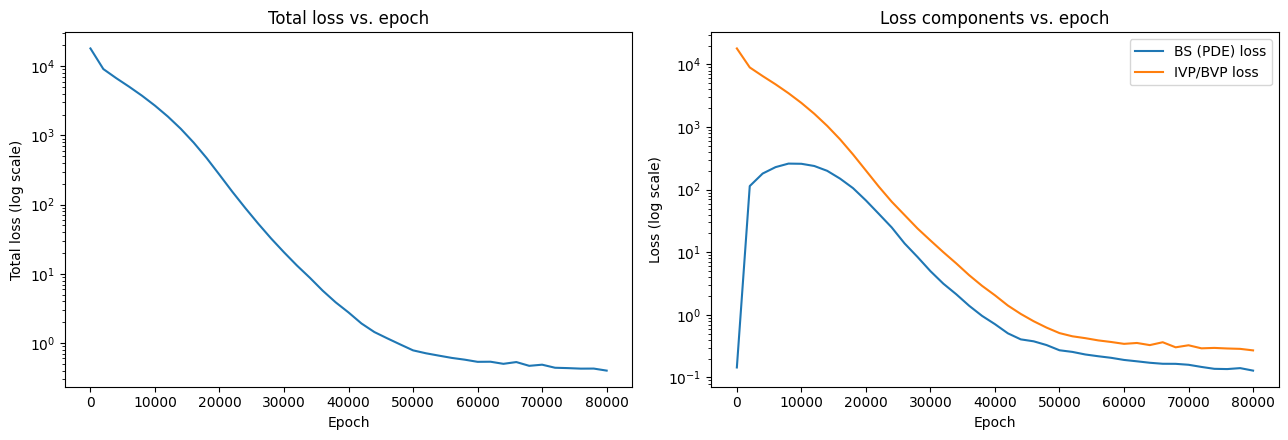

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(loss_epochs, loss_total_history)
axes[0].set_yscale("log")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Total loss (log scale)")
axes[0].set_title("Total loss vs. epoch")

axes[1].plot(loss_epochs, loss_bs_history, label="BS (PDE) loss")
axes[1].plot(loss_epochs, loss_ivp_bvp_history, label="IVP/BVP loss")
axes[1].set_yscale("log")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss (log scale)")
axes[1].set_title("Loss components vs. epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## Evaluate on 100 x 100 mesh 

In [9]:
N_test = 100

s = np.linspace(S_range[0], S_range[1], N_test)
t = np.linspace(t_range[0], t_range[1], N_test)
s_grid, t_grid = np.meshgrid(s, t)
s_flat = s_grid.flatten()
t_flat = t_grid.flatten()

X_test = torch.tensor(np.column_stack((t_flat, s_flat)), dtype=torch.float, device=DEVICE)

with torch.no_grad():
    # Guard the exact t = T row (tau = 0): the repo's get_analytical_soln has
    # no eps-clamp and can hit log(S/K)/0 -> NaN there; use the exact payoff instead.
    tau = T - X_test[:, 0]
    eps = 1e-6
    t_safe = torch.where(tau < eps, X_test[:, 0] - eps, X_test[:, 0])

    V_true = euro_call_data.get_analytical_soln(X_test[:, 1], t_safe)
    payoff = torch.clamp(X_test[:, 1] - K, min=0.0)
    V_true = torch.where(tau < eps, payoff, V_true).reshape(-1, 1)

    model.eval()
    V_pinn = model(X_test).reshape(-1, 1)

error = V_pinn - V_true
mse = torch.mean(error ** 2).item()
rmse = mse ** 0.5
mae = torch.mean(torch.abs(error)).item()
max_abs_error = torch.max(torch.abs(error)).item()
correlation = np.corrcoef(
    V_pinn.detach().cpu().numpy().reshape(-1),
    V_true.detach().cpu().numpy().reshape(-1),
)[0, 1]

print("Paper Original Forward PINN vs. Analytical BS, on your 100x100 mesh")
print("-" * 65)
print(f"MSE:         {mse:.8f}")
print(f"RMSE:        {rmse:.8f}")
print(f"MAE:         {mae:.8f}")
print(f"Max Abs Err: {max_abs_error:.8f}")
print(f"Correlation: {correlation:.8f}")

Paper Original Forward PINN vs. Analytical BS, on your 100x100 mesh
-----------------------------------------------------------------
MSE:         0.05937624
RMSE:        0.24367241
MAE:         0.17842734
Max Abs Err: 1.89505434
Correlation: 0.99998212


## Analytical vs. PINN surfaces

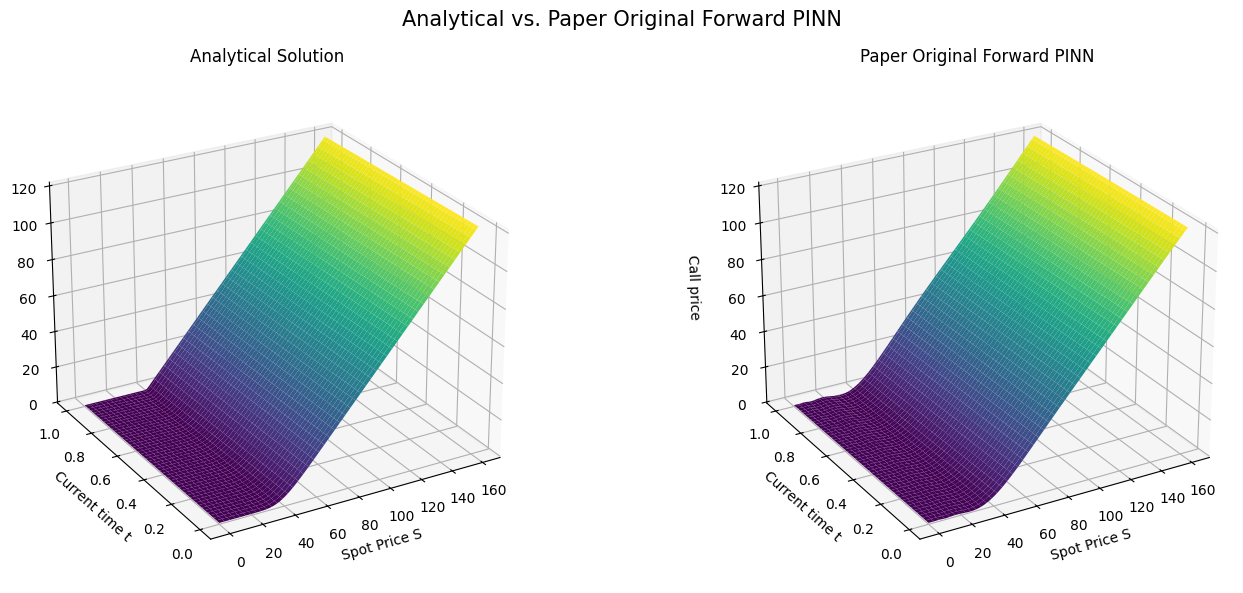

In [7]:
V_true_surface = V_true.detach().cpu().numpy().reshape(N_test, N_test)
V_pinn_surface = V_pinn.detach().cpu().numpy().reshape(N_test, N_test)
error_surface = error.detach().cpu().numpy().reshape(N_test, N_test)

fig = plt.figure(figsize=(15, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(s_grid, t_grid, V_true_surface, cmap="viridis", edgecolor="none")
ax1.set_title("Analytical Solution")
ax1.set_xlabel("Spot Price S")
ax1.set_ylabel("Current time t")
ax1.set_zlabel("Call price", labelpad=10)

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(s_grid, t_grid, V_pinn_surface, cmap="viridis", edgecolor="none")
ax2.set_title("Paper Original Forward PINN")
ax2.set_xlabel("Spot Price S")
ax2.set_ylabel("Current time t")
ax2.set_zlabel("Call price", labelpad=10)

z_min = min(V_true_surface.min(), V_pinn_surface.min())
z_max = max(V_true_surface.max(), V_pinn_surface.max())
ax1.set_zlim(z_min, z_max)
ax2.set_zlim(z_min, z_max)
ax1.view_init(elev=25, azim=-120)
ax2.view_init(elev=25, azim=-120)

fig.suptitle("Analytical vs. Paper Original Forward PINN", fontsize=15)
plt.tight_layout()
plt.show()

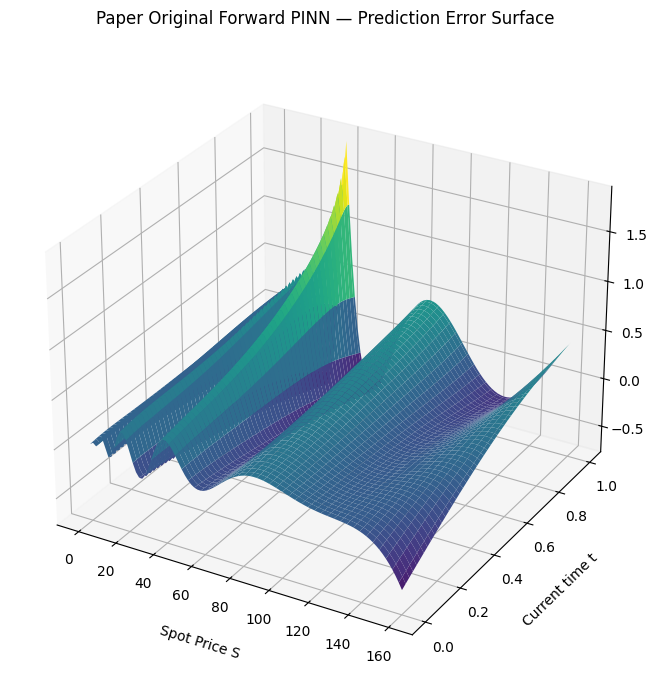

In [8]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(s_grid, t_grid, error_surface, cmap="viridis", edgecolor="none")
ax.set_xlabel("Spot Price S", labelpad=12)
ax.set_ylabel("Current time t", labelpad=12)
ax.set_zlabel("Prediction error (PINN - Analytical)", labelpad=12)
ax.set_title("Paper Original Forward PINN — Prediction Error Surface", pad=18)
ax.view_init(elev=28, azim=-60)
plt.tight_layout()
plt.show()